--- STEP 1: EDA & DATA CLEANING ---
Shape: (3657, 20)

Missing Values Before Cleaning:
Series([], dtype: int64)

Median Price: 295000000.0
High_Price
0    1830
1    1826
Name: count, dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_9704\3889618183.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df_clean, x="High_Price", y="Bedrooms", palette="Set2")
C:\Users\DELL\AppData\Local\Temp\ipykernel_9704\3889618183.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df_clean, x="High_Price", y="dist_to_lekki", palette="Set2")


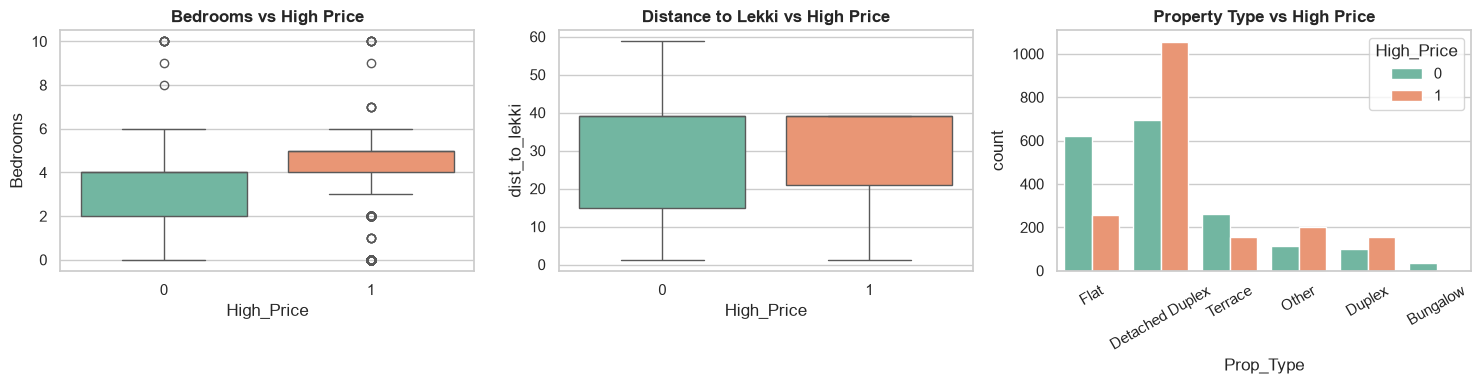


--- STEP 2: ENCODING & SCALING ---

--- STEP 3: MODEL TRAINING & EVALUATION ---


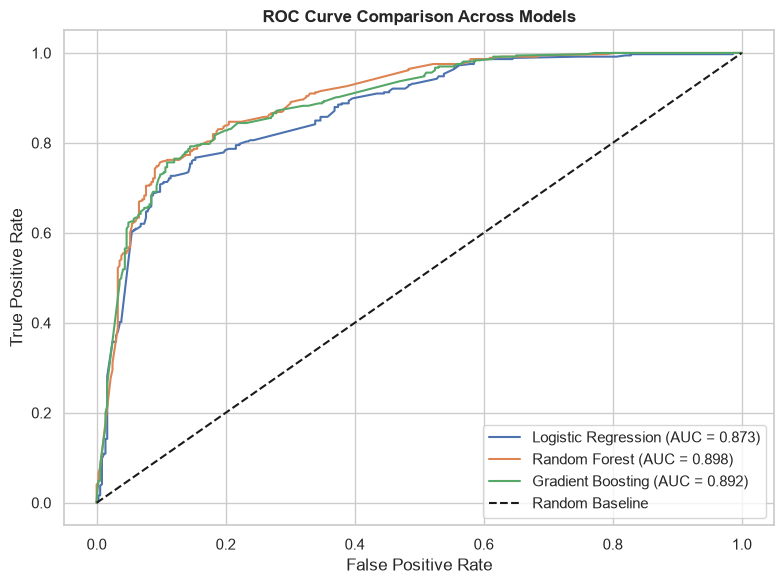


--- MODEL PERFORMANCE COMPARISON TABLE ---
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
      Random Forest     0.827      0.887   0.749     0.812    0.898
  Gradient Boosting     0.821      0.864   0.762     0.810    0.892
Logistic Regression     0.787      0.787   0.787     0.787    0.873

Best Performing Model: Random Forest
          Feature  Importance
         Bedrooms       0.223
    Island_x_Beds       0.187
        Bathrooms       0.117
              lat       0.064
Neighborhood_Tier       0.061
              lon       0.052
    dist_to_lekki       0.043
   Prop_Type_Flat       0.043
    Location_Ajah       0.039
    dist_to_ikeja       0.039


C:\Users\DELL\AppData\Local\Temp\ipykernel_9704\3889618183.py:156: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", palette="Blues_r")


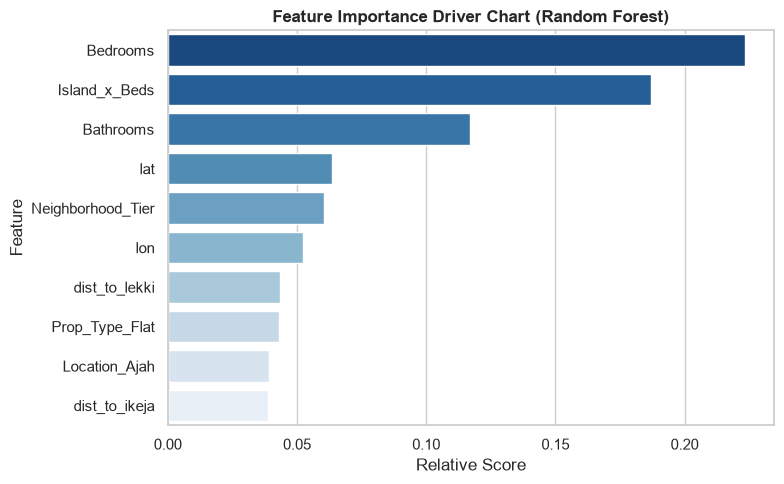

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

# Models for Multi-Model Evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

# STEP 1: DATA CLEANING & EDA
print("--- STEP 1: EDA & DATA CLEANING ---")
df = pd.read_csv("Lagos_houses_prices.csv")
print("Shape:", df.shape)

# 1. Inspect Missing Values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Remove duplicate rows
df = df.drop_duplicates()

# 3. Impute Missing Values (Median for numeric columns; none are missing here, kept as a safety step)
num_cols = ["Bedrooms", "Bathrooms", "dist_to_lekki", "dist_to_ikeja", "Luxury_Score", "Neighborhood_Tier"]
imputer = SimpleImputer(strategy="median")
df[num_cols] = imputer.fit_transform(df[num_cols])

# 4. Create the target: High_Price = 1 if Price is above the median, else 0
median_price = df["Price"].median()
df["High_Price"] = (df["Price"] > median_price).astype(int)
print("\nMedian Price:", median_price)
print(df["High_Price"].value_counts())

# 5. Drop text/identifier columns and Price (Price would leak the answer)
df_clean = df.drop(columns=["Title", "Full_Location", "Price"]).copy()
df_clean.to_csv("cleaned_lagos_houses.csv", index=False)

# Visual EDA: Numerical Distributions and Target Separation
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(ax=axes[0], data=df_clean, x="High_Price", y="Bedrooms", palette="Set2")
axes[0].set_title("Bedrooms vs High Price", fontweight="bold")

sns.boxplot(ax=axes[1], data=df_clean, x="High_Price", y="dist_to_lekki", palette="Set2")
axes[1].set_title("Distance to Lekki vs High Price", fontweight="bold")

sns.countplot(ax=axes[2], data=df_clean, x="Prop_Type", hue="High_Price", palette="Set2")
axes[2].set_title("Property Type vs High Price", fontweight="bold")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("eda_charts.png", dpi=150, bbox_inches="tight")
plt.show()

# STEP 2: FEATURE ENCODING, SCALING & TRAIN-TEST SPLIT
print("\n--- STEP 2: ENCODING & SCALING ---")

# Categorical Encoding (One-Hot Encoding)
df_encoded = pd.get_dummies(df_clean, columns=["Prop_Type", "Location"], drop_first=True)

# Separate Features (X) and Target (y)
X = df_encoded.drop(columns=["High_Price"])
y = df_encoded["High_Price"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling (Fit on Train, Transform on both Train and Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for easy handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

# STEP 3: MULTI-MODEL TRAINING & COMPARISON
print("\n--- STEP 3: MODEL TRAINING & EVALUATION ---")

# Define candidate models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

results_list = []
plt.figure(figsize=(8, 6))

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    # Plot ROC Curve for each model
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Finalize ROC Curve Plot
plt.plot([0, 1], [0, 1], "k--", label="Random Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison Across Models", fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Display Metrics Comparison Table
metrics_df = pd.DataFrame(results_list).sort_values(by="F1-Score", ascending=False)
print("\n--- MODEL PERFORMANCE COMPARISON TABLE ---")
print(metrics_df.round(3).to_string(index=False))

# Identify Best Model based on F1-Score
best_model_name = metrics_df.iloc[0]["Model"]
print(f"\nBest Performing Model: {best_model_name}")

# STEP 4: FEATURE IMPORTANCE OF THE BEST MODEL
best_model = models[best_model_name]

if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
else:
    importances = np.abs(best_model.coef_[0])

feat_imp = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)
print(feat_imp.head(10).round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", palette="Blues_r")
plt.title(f"Feature Importance Driver Chart ({best_model_name})", fontweight="bold")
plt.xlabel("Relative Score")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()